# 08. Rede pública, filantrópica e privada

Em que tipo de hospital as mulheres com câncer de mama são tratadas, e isso se associa a diferenças no estádio e no tempo de espera?

Antes de responder, é preciso separar duas ideias que costumam ser confundidas. A primeira é a natureza jurídica do hospital: ele pode ser público (federal, estadual ou municipal), filantrópico (entidade sem fins lucrativos, como as Santas Casas) ou privado com fins lucrativos. A segunda é quem paga o atendimento: o SUS, um plano de saúde ou a própria paciente. As duas coisas não coincidem. A maior parte dos hospitais filantrópicos, e muitos privados, atende principalmente pacientes do SUS.

O RHC informa o hospital (pelo código CNES), o que permite descobrir sua natureza jurídica no cadastro do CNES. Ele também informa a origem do encaminhamento da paciente (SUS, não SUS ou por conta própria), que é a melhor aproximação disponível de quem financia o atendimento. Nenhuma base pública registra diretamente se a paciente tem plano de saúde.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from mama import codigos as c, graficos as g
from mama.config import FONTE_RHC
from mama.analises import base, rede, estadiamento as est, tempos

pd.set_option("display.max_columns", 20)
rhc = rede.com_natureza(base.rhc(), "cnes_hosp")
ORDEM_NAT = rede.ORDEM_NATUREZA + [c.SEM_INFO]

## Natureza jurídica dos hospitais que atendem as pacientes

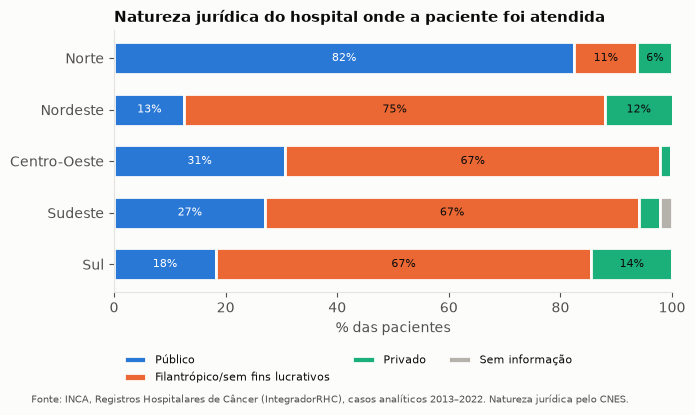

In [2]:
nat = base.distribuicao(rhc, "natureza", ordem=ORDEM_NAT)
base.salvar_tabela(nat, "08_natureza_hospital_regiao", index=True)
fig, ax = g.empilhadas_100(nat, "Natureza jurídica do hospital onde a paciente foi atendida")
g.salvar(fig, "08_natureza_hospital_regiao", FONTE_RHC + " Natureza jurídica pelo CNES.")
plt.show()

O cuidado do câncer de mama no Brasil é sustentado majoritariamente por hospitais filantrópicos: eles atendem dois terços ou mais das pacientes no Nordeste, Centro-Oeste, Sudeste e Sul. O Norte é a exceção, com 82% das pacientes em hospitais públicos, já que a região tem poucas instituições filantrópicas de grande porte. Hospitais privados com fins lucrativos respondem por menos de 15% em todas as regiões.

## Quem encaminhou a paciente

A tabela mostra a origem do encaminhamento por natureza do hospital. Ela deixa claro que natureza jurídica e financiamento são coisas diferentes.

In [3]:
origem = pd.crosstab(rhc.natureza, rhc.origem_encaminhamento, normalize="index").mul(100).round(1)
origem = origem.reindex(ORDEM_NAT)[["SUS", "Não SUS", "Conta própria", c.SEM_INFO]]
base.salvar_tabela(origem, "08_origem_encaminhamento_por_natureza", index=True)
display(origem)
origem_reg = base.distribuicao(rhc, "origem_encaminhamento", ordem=["SUS", "Não SUS", "Conta própria", c.SEM_INFO])
base.salvar_tabela(origem_reg, "08_origem_encaminhamento_regiao", index=True)
origem_reg

origem_encaminhamento,SUS,Não SUS,Conta própria,Sem informação
natureza,,,,
Público,52.7,6.5,1.7,39.1
Filantrópico/sem fins lucrativos,49.8,12.2,1.8,36.2
Privado,79.3,8.7,1.4,10.7
Sem informação,11.4,0.0,0.0,88.6


origem_encaminhamento,SUS,Não SUS,Conta própria,Sem informação
regiao_res,,,,
Norte,73.8,17.4,0.6,8.2
Nordeste,63.5,16.6,5.4,14.5
Centro-Oeste,57.1,8.1,1.9,32.8
Sudeste,37.0,5.9,0.3,56.8
Sul,67.5,11.8,0.4,20.3


Até nos hospitais privados, quase 80% das pacientes chegaram encaminhadas pelo SUS. Isso acontece porque os hospitais privados que mantêm registro de câncer são, em geral, conveniados ao SUS. A origem do encaminhamento está sem informação em 57% dos casos do Sudeste (de novo, por causa da base de São Paulo), então ela é útil para Norte, Nordeste e Sul, mas não para comparar todas as regiões.

A conclusão é que o RHC é, na prática, uma base majoritariamente de pacientes do SUS, e que ele não permite uma comparação limpa entre "rede pública" e "rede privada" no sentido de quem paga. O que ele permite é comparar os tipos de hospital.

## Estádio e tempo de espera por tipo de hospital

In [4]:
est_nat = est.avancado(rhc, ["natureza"])
tempo_nat = tempos.resumo(rhc, "dias_diagnostico_tratamento", ["natureza"])
est_origem = est.avancado(rhc, ["origem_encaminhamento"])
tempo_origem = tempos.resumo(rhc, "dias_diagnostico_tratamento", ["origem_encaminhamento"])
for nome, t in [("estadio_natureza", est_nat), ("tempo_natureza", tempo_nat),
                ("estadio_origem", est_origem), ("tempo_origem", tempo_origem)]:
    base.salvar_tabela(t, f"08_{nome}")
display(est_nat); display(tempo_nat); display(est_origem); display(tempo_origem)

,natureza,n,eventos,pct,ic_inf,ic_sup
0,Filantrópico/sem fins lucrativos,182475,66637,36.5,36.3,36.7
1,Privado,21041,9122,43.4,42.7,44.0
2,Público,61605,26528,43.1,42.7,43.5
3,Sem informação,3554,1277,35.9,34.4,37.5


,natureza,n,mediana,p25,p75,pct_mais_60_dias,pct_mais_6_meses,pct_mais_1_ano
0,Filantrópico/sem fins lucrativos,216713,66.0,35.0,117.0,54.1,12.9,3.4
1,Privado,26177,52.0,24.0,98.0,43.5,11.1,3.5
2,Público,78934,90.0,50.0,153.0,68.0,19.1,5.6
3,Sem informação,3560,62.0,25.0,103.0,51.9,6.1,1.2


,origem_encaminhamento,n,eventos,pct,ic_inf,ic_sup
0,Conta própria,4749,2101,44.2,42.8,45.7
1,Não SUS,25025,7832,31.3,30.7,31.9
2,SUS,128905,54641,42.4,42.1,42.7
3,Sem informação,109996,38990,35.4,35.2,35.7


,origem_encaminhamento,n,mediana,p25,p75,pct_mais_60_dias,pct_mais_6_meses,pct_mais_1_ano
0,Conta própria,5545,55.0,31.0,93.0,45.5,7.7,1.9
1,Não SUS,31704,58.0,30.0,119.0,48.8,16.4,4.4
2,SUS,170180,70.0,37.0,127.0,57.0,15.0,4.2
3,Sem informação,117955,72.0,40.0,122.0,58.6,12.7,3.6


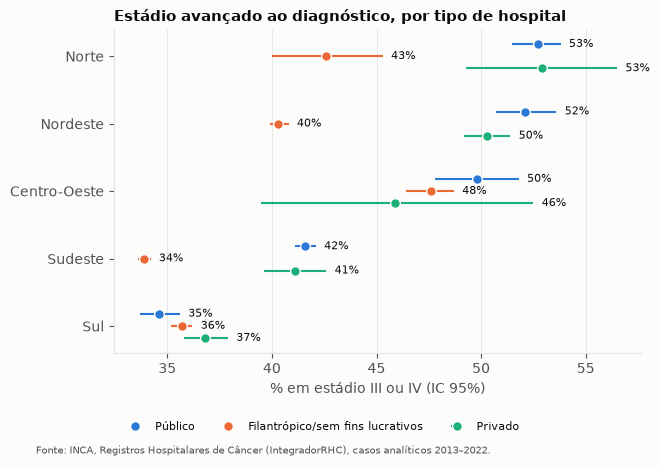

In [5]:
t = est.avancado(rhc[rhc.natureza != c.SEM_INFO], ["regiao_res", "natureza"])
fig, ax = g.pontos_ic(t, "regiao_res", "natureza", "Estádio avançado ao diagnóstico, por tipo de hospital",
                      "% em estádio III ou IV (IC 95%)", ordem_cat=c.REGIOES, ordem_grupo=rede.ORDEM_NATUREZA,
                      figsize=(6.8, 4.2))
g.salvar(fig, "08_estadio_avancado_natureza", FONTE_RHC)
plt.show()

No conjunto do país, hospitais públicos e privados recebem mais casos avançados (43% em ambos) do que os filantrópicos (37%). Já o tempo de espera separa bem os três: mediana de 90 dias entre diagnóstico e tratamento nos públicos, 66 nos filantrópicos e 52 nos privados. O gráfico por região mostra que essa diferença não é uniforme, e parte dela vem de onde cada tipo de hospital está: os públicos concentram-se no Norte, que tem os piores indicadores.

Pela origem do encaminhamento, que é a medida mais próxima de financiamento, pacientes encaminhadas de fora do SUS chegam com menos casos avançados (31% contra 42%) e esperam menos (mediana de 58 contra 70 dias) do que as encaminhadas pelo SUS. Mas, como a variável falta em boa parte dos casos, essa comparação serve como indício, não como medida precisa da diferença entre as redes.

## O que levar para o TCC

O tratamento do câncer de mama no Brasil depende fortemente dos hospitais filantrópicos conveniados ao SUS, exceto no Norte, onde predomina o hospital público. Hospitais públicos atendem mais casos avançados e têm esperas mais longas. Os dados públicos não permitem medir diretamente a diferença entre pacientes do SUS e de planos de saúde. Para essa comparação, a literatura (por exemplo, estudos com dados da ANS ou de coortes hospitalares) teria de ser usada na discussão.